# VisA 데이터셋을 활용한 PCB 이상 탐지 및 PaDiM 성능 분석

## 1. 프로젝트 개요

이번 프로젝트에서는 제조업의 비전 검사에서 발생하는 불량 데이터 부족 문제를 고려하여 정상 이미지만으로 이상을 탐지하는 방법을 실습하였다.

제조 현장에서는 불량 유형을 모두 수집하기 어렵고, 처음 보는 결함이 발생할 수도 있다. 따라서 정상 제품의 특징을 기준으로 이상 여부를 판단하는 방식에 관심을 가졌다.

강의에서 소개한 PaDiM을 중심으로 PCB 이미지의 이상 여부를 판정하고, 결함이 의심되는 영역을 시각화하였다. 이후 임계값과 특징 차원을 변경하는 실험을 진행하고, One-Class SVM과 AutoEncoder의 결과도 비교하였다.

이번 작업의 목적은 단순히 모델을 실행하는 것에 그치지 않고, 결과가 달라지는 원인을 살펴보면서 모델의 성능과 한계를 이해하는 것이다.

## 1.1 프로젝트 목표

첫 번째 목표는 VisA 데이터셋의 정상 이미지로 PaDiM 모델을 구성하고, 테스트 이미지에서 정상과 불량을 구별하는 것이다.

두 번째 목표는 AUROC, AUPRC, F1, Precision, Recall 및 혼동행렬을 이용해 모델의 성능을 평가하는 것이다.

세 번째 목표는 임계값과 특징 차원을 변경하면서 오탐, 미탐, 탐지 성능 및 계산 시간의 변화를 비교하는 것이다.

마지막으로 다른 이상 탐지 모델과의 결과를 비교하고, 실제 제조업 검사에 적용하려면 어떤 검증이 더 필요한지 정리하고자 하였다.

## 1.2 실험 데이터와 범위

실험에는 VisA 데이터셋의 PCB4 이미지를 사용하였다. 정상 이미지 1,005장과 불량 이미지 100장이 있으며, 정상 이미지의 80%를 학습 분할로 사용하고 나머지 20%와 불량 이미지 전체를 테스트에 사용하였다.

실행 시간을 고려해 이번 PaDiM 학습에는 정상 이미지 200장을 선택하였다. 원래 학습 분할은 804장이므로 전체 데이터를 이용한 결과와 직접적으로 동일한 조건은 아니다.

또한 AutoEncoder는 빠른 비교를 위해 2 epoch만 학습하였다. 따라서 세 모델의 결과는 이번 설정에서 나타난 차이로 해석하고, 각 알고리즘의 일반적인 우열을 확정하는 자료로 사용하지 않았다.

## 1.3 진행 순서

먼저 실행 환경과 데이터 구성을 확인하고 이미지 전처리를 진행하였다. 이후 ResNet18로 특징을 추출한 뒤 PaDiM의 정상 분포를 구성하였다.

PaDiM의 기본 성능을 확인한 다음 임계값 실험과 특징 차원 실험을 진행하였다. 마지막에는 One-Class SVM과 AutoEncoder를 비교하고, 그래프와 결과 파일을 정리하였다.


## 2. 실행 환경 확인

### 2.1 Python 라이브러리와 GPU 확인

이미지 처리에는 PIL과 torchvision을 사용하고, 모델 계산에는 PyTorch를 사용하였다. 평가 지표는 scikit-learn으로 계산하였다.

실습 중에는 모델 구현보다도 라이브러리 버전이나 실행 환경 때문에 오류가 발생하는 경우가 있었다. 그래서 학습을 시작하기 전에 필요한 패키지와 CUDA 사용 가능 여부를 먼저 확인하였다.


In [1]:
# 01 | 필수 패키지 자동 점검
import os,sys,time,json,random,hashlib,importlib.util,subprocess
from pathlib import Path
for mod,pkg in [("numpy","numpy"),("pandas","pandas"),("PIL","pillow"),("matplotlib","matplotlib"),("sklearn","scikit-learn"),("tqdm","tqdm")]:
    if importlib.util.find_spec(mod) is None:
        print("설치:",pkg,flush=True)
        subprocess.check_call([sys.executable,"-m","pip","install",pkg])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.nn import functional as F
from torchvision import models,transforms
from torch.utils.data import Dataset,DataLoader
from sklearn.metrics import roc_auc_score,average_precision_score,roc_curve,confusion_matrix,f1_score,precision_score,recall_score
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
print("01 OK | Python",sys.version.split()[0],"| torch",torch.__version__,"| cuda",torch.cuda.is_available(),flush=True)

C:\Users\USER\.conda\envs\cv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


01 OK | Python 3.12.14 | torch 2.14.0+cu130 | cuda True


### 실행 결과 확인

Python 3.12.14와 PyTorch 2.14.0 환경에서 CUDA 사용이 가능한 것을 확인하였다.

IProgress 관련 경고가 출력되었지만 이후 셀까지 정상 실행되었다. 이번 실행에서는 해당 경고가 모델 계산을 중단시키지는 않았다.


### 2.2 실험 조건 설정

실험을 다시 실행했을 때 조건이 달라지지 않도록 random seed를 42로 설정하였다.

입력 이미지는 192×192 크기로 통일하고, PaDiM의 특징 맵은 14×14 크기를 사용하였다. 정상 학습 이미지는 200장으로 제한하였다.

원본 실습보다 계산량을 줄여 안정적으로 끝까지 실행하는 것을 먼저 목표로 했다. 다만 이미지 크기나 학습 이미지 수를 줄이면 작은 결함을 탐지하는 성능에도 영향을 줄 수 있으므로, 이후 결과를 해석할 때 이 조건을 함께 고려해야 한다.


In [2]:
# 02 | 프로젝트 자동 위치 확인 + 사용자 설정
DEFAULT=Path(r"C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\07_Anomaly_detection")
candidates=[DEFAULT,Path.cwd(),Path.cwd()/"07_Anomaly_detection",Path.home()/"Desktop"/"ERICA_X_MODULABS_CV"/"07_Anomaly_detection"]
ROOT=next((p.resolve() for p in candidates if (p/"VisA"/"pcb4"/"image_anno.csv").is_file()),None)
if ROOT is None: raise FileNotFoundError("VisA/pcb4/image_anno.csv가 없습니다. 이 파일을 07_Anomaly_detection 폴더에 넣어 주세요.")
os.chdir(ROOT)
CSV=ROOT/"VisA"/"pcb4"/"image_anno.csv"
OUT=ROOT/"padim_outputs"
CACHE=OUT/"feature_cache"
CACHE.mkdir(parents=True,exist_ok=True)
SEED=42
IMAGE_SIZE=192
GRID=14
MAX_TRAIN_IMAGES=200  # 804장 전체를 학습하려면 None
AE_EPOCHS=2
DEVICE=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
BATCH=8 if DEVICE.type=="cuda" else 4
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if DEVICE.type=="cpu": torch.set_num_threads(min(4,os.cpu_count() or 1))
print("02 OK | 폴더:",ROOT,"| 장치:",DEVICE,"| 실제 학습 이미지 상한:",MAX_TRAIN_IMAGES,flush=True)

02 OK | 폴더: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\07_Anomaly_detection | 장치: cuda:0 | 실제 학습 이미지 상한: 200


### 설정에 대한 생각

GPU를 사용하도록 설정되었으며 정상 학습 이미지 수는 최대 200장으로 지정되었다.

실행 가능성을 먼저 확보한 점은 좋았지만, 학습 이미지 수를 줄인 만큼 이 조건의 결과를 전체 804장 학습 결과와 그대로 비교해서는 안 된다고 생각한다.


## 3. 데이터셋 구성과 전처리

### 3.1 정상 및 불량 데이터 구분

PaDiM은 정상 데이터에서 추출한 특징의 분포를 학습하는 방식이므로, 학습 과정에 어떤 이미지가 포함되는지가 중요하다.

VisA의 image_anno.csv 파일을 기준으로 정상과 불량을 구분하고, 정상 데이터만 학습에 사용하도록 구성하였다. 불량 이미지는 모델 성능 평가에 사용하였다.

이번 실험에서는 정상 이미지를 80%와 20%로 나눈 뒤 학습 분할에서 200장을 선택하였다. 테스트에는 나머지 정상 이미지와 전체 불량 이미지를 사용하였다.


In [3]:
# 03 | VisA CSV 직접 로드: 원본 분할(정상 80%/20% + 불량 전체)
df=pd.read_csv(CSV)
required={"image","label","mask"}
if not required.issubset(df.columns):raise ValueError("CSV 필수 컬럼이 없습니다: "+str(required-df.columns.to_series().index.to_set()))
df["label"]=df["label"].astype(str).str.lower().str.strip()
normal=df[df.label=="normal"]
bad=df[df.label!="normal"]
cut=int(len(normal)*.8)
def resolve(s):
    if pd.isna(s):return None
    s=str(s).strip().replace("\\","/").lstrip("./")
    if not s:return None
    p=Path(s)
    options=[p] if p.is_absolute() else [ROOT/"VisA"/p,ROOT/"VisA"/"pcb4"/p]
    return next((q.resolve() for q in options if q.is_file()),None)
def records(frame):
    output=[]
    for _,r in frame.iterrows():
        img=resolve(r["image"])
        if img is None:raise FileNotFoundError("이미지 경로 오류: "+str(r["image"]))
        output.append({"image":img,"mask":resolve(r["mask"]),"label":int(r["label"]!="normal"),"type":r["label"]})
    return output
train_full=records(normal.iloc[:cut])
test_rows=records(pd.concat([normal.iloc[cut:],bad],ignore_index=True))
if MAX_TRAIN_IMAGES is not None and len(train_full)>MAX_TRAIN_IMAGES:
    indexes=sorted(np.random.default_rng(SEED).choice(len(train_full),MAX_TRAIN_IMAGES,replace=False))
    train_rows=[train_full[i] for i in indexes]
else:train_rows=train_full
labels=np.array([r["label"] for r in test_rows],dtype=int)
assert len(train_rows)>=3 and (labels==0).any() and (labels==1).any()
print("03 OK | 정상 전체",len(normal),"| 불량 전체",len(bad))
print("정상 학습 분할",len(train_full),"| 실제 학습",len(train_rows),"| 테스트 정상",int((labels==0).sum()),"| 테스트 불량",int((labels==1).sum()),flush=True)

03 OK | 정상 전체 1005 | 불량 전체 100
정상 학습 분할 804 | 실제 학습 200 | 테스트 정상 201 | 테스트 불량 100


### 데이터 구성 결과

전체 정상 이미지는 1,005장, 불량 이미지는 100장으로 확인되었다.

정상 학습 분할은 804장이지만 실제 학습에는 200장이 사용되었다. 테스트에는 정상 201장과 불량 100장이 사용되었다.

테스트 데이터에는 실제 제조 현장보다 불량 이미지의 비율이 높을 수 있다. 따라서 이번 실험의 Precision이나 오탐 개수를 현장 불량률에 그대로 적용할 수는 없다.


### 3.2 이미지 전처리와 실제 결함 마스크 확인

이미지의 크기가 서로 다르면 모델에 입력하거나 특징을 비교할 때 문제가 발생하므로, 모든 입력을 같은 크기로 변환하였다.

ResNet18의 사전학습 가중치에 맞춰 ImageNet 평균과 표준편차로 정규화하였다.

또한 VisA에서는 결함이 있는 위치를 나타내는 마스크도 제공한다. 이상 탐지 결과를 확인하기 전에 실제 결함 마스크가 정상적으로 연결되는지 살펴보았다.

이 마스크는 이후 모델이 강조한 영역과 실제 결함 위치를 비교하는 데 사용할 수 있다.


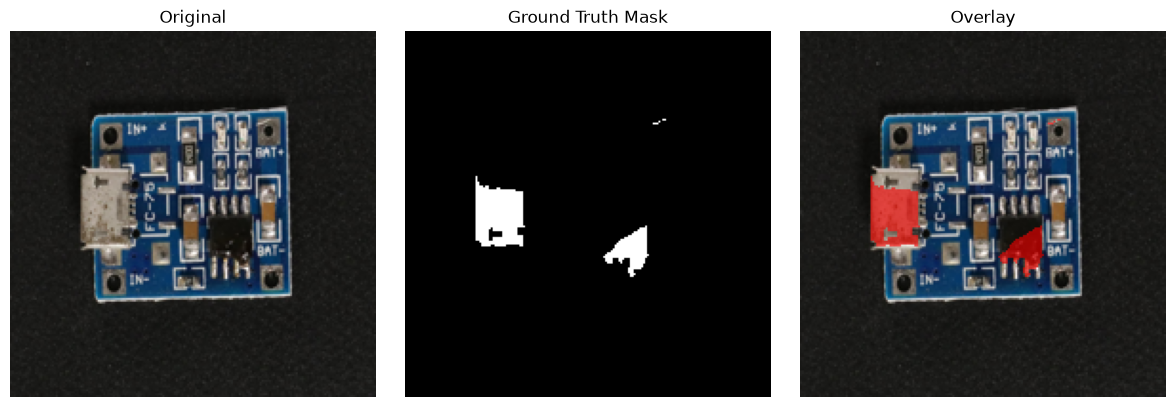

마스크 정상 | 실제 결함 픽셀: 1021
04 OK | batch (8, 3, 192, 192) | workers=0


In [4]:
# 04 | DataLoader(num_workers=0) 및 GT 마스크 검사
transform=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
class VisaDataset(Dataset):
    def __init__(self,rows):self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        with Image.open(self.rows[i]["image"]) as im:
            x=transform(im.convert("RGB"))
        return {"image":x,"label":self.rows[i]["label"]}
train_data=VisaDataset(train_rows);test_data=VisaDataset(test_rows)
train_loader=DataLoader(train_data,batch_size=BATCH,shuffle=False,num_workers=0,pin_memory=False)
test_loader=DataLoader(test_data,batch_size=BATCH,shuffle=False,num_workers=0,pin_memory=False)
sample_batch=next(iter(test_loader))
assert tuple(sample_batch["image"].shape[1:])==(3,IMAGE_SIZE,IMAGE_SIZE)
valid_mask_row=None
for r in test_rows:
    if r["label"]==0 or r["mask"] is None:continue
    try:
        with Image.open(r["mask"]) as im: pix=np.asarray(im.convert("L"))
        if np.any(pix>0):
            valid_mask_row=r;break
    except (OSError,ValueError):pass
if valid_mask_row:
    with Image.open(valid_mask_row["image"]) as im: raw=np.asarray(im.convert("RGB").resize((IMAGE_SIZE,IMAGE_SIZE)))
    with Image.open(valid_mask_row["mask"]) as im: mask=np.asarray(im.convert("L").resize((IMAGE_SIZE,IMAGE_SIZE),Image.NEAREST))>0
    overlay=raw.astype(np.float32)/255
    overlay[mask]=.4*overlay[mask]+.6*np.array([1.,0.,0.],dtype=np.float32)
    fig,axs=plt.subplots(1,3,figsize=(12,4))
    for ax,img,title in zip(axs,[raw,mask,overlay],["Original","Ground Truth Mask","Overlay"]):
        ax.imshow(img,cmap="gray" if title=="Ground Truth Mask" else None);ax.set_title(title);ax.axis("off")
    fig.tight_layout();fig.savefig(OUT/"ground_truth_preview.png",dpi=130);plt.show();plt.close(fig)
    print("마스크 정상 | 실제 결함 픽셀:",int(mask.sum()))
else:print("경고: 비어 있지 않은 정답 마스크를 찾지 못했습니다. 빈 마스크를 결함으로 꾸미지 않습니다.")
print("04 OK | batch",tuple(sample_batch["image"].shape),"| workers=0",flush=True)

### 확인 결과

입력 배치의 크기는 8×3×192×192로 확인되었다.

실제 결함 마스크가 포함된 샘플도 확인되었으며, 선택된 마스크에는 전처리 후 1,021개의 결함 픽셀이 있었다.

이 결과는 데이터와 마스크가 정상적으로 연결되었음을 보여준다. 아직 모델의 예측 결과와 정답 마스크를 정량적으로 비교한 것은 아니므로, 위치 탐지 정확도가 검증된 것은 아니다.


## 4. PaDiM 모델 구현

### 4.1 ResNet18을 이용한 특징 추출

PaDiM은 일반적인 이미지 분류 모델처럼 정상과 불량을 모두 이용해 CNN을 학습하는 방식이 아니다.

사전학습된 CNN에서 이미지 특징을 추출하고, 정상 이미지에서 얻은 특징들의 통계적 분포를 구성한다.

이번에는 ResNet18의 layer1, layer2, layer3에서 특징을 추출하였다. 서로 다른 계층의 특징을 결합해 총 448개 채널을 사용하였고, 위치별로 비교할 수 있도록 14×14 크기로 맞추었다.

CNN의 가중치는 별도로 학습시키지 않았다. 따라서 여기서 말하는 PaDiM 학습은 CNN을 처음부터 학습하는 것이 아니라, 추출된 정상 특징의 평균과 공분산을 추정하는 과정이다.


In [5]:
# 05 | 사전학습 ResNet18 고정 특징 추출기. 실패 시 신뢰 제한을 분명히 표시.
WEIGHT_STATUS="pretrained"
try:
    backbone=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
except Exception as e:
    WEIGHT_STATUS="untrained_fallback"
    print("주의: ImageNet 사전학습 가중치 다운로드/로드 실패:",str(e)[:200])
    print("무작위 CNN으로 진행하며 이 실행의 성능은 제출용 확정 지표가 아닙니다.")
    backbone=models.resnet18(weights=None)
backbone=backbone.to(DEVICE).eval()
for p in backbone.parameters():p.requires_grad_(False)
class Extractor(nn.Module):
    def __init__(self,net):super().__init__();self.net=net
    def forward(self,x):
        m=self.net
        x=m.maxpool(m.relu(m.bn1(m.conv1(x))))
        a=m.layer1(x);b=m.layer2(a);c=m.layer3(b)
        z=torch.cat([F.adaptive_avg_pool2d(v,(GRID,GRID)) for v in [a,b,c]],dim=1)
        return z.permute(0,2,3,1).reshape(z.shape[0],GRID*GRID,448)
extractor=Extractor(backbone).to(DEVICE).eval()
with torch.inference_mode():check=extractor(sample_batch["image"][:1].to(DEVICE))
assert tuple(check.shape)==(1,GRID*GRID,448)
del check
print("05 OK | ResNet18 특징 448채널 | patches",GRID*GRID,"|",WEIGHT_STATUS,flush=True)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\USER/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 62.5MB/s]


05 OK | ResNet18 특징 448채널 | patches 196 | pretrained


### 특징 추출 결과

ResNet18의 사전학습 가중치가 정상적으로 로드되었고, 이미지 한 장에서 196개 위치의 448차원 특징을 얻는 것을 확인하였다.

사전학습된 특징을 사용했기 때문에 정상 이미지만으로도 분포를 구성할 수 있었다. 다만 Backbone 종류가 달라지면 특징 표현도 달라질 수 있으므로, 다른 구조와 비교할 때는 동일한 데이터 조건을 유지해야 한다.


### 4.2 특징 데이터 저장과 메모리 관리

PaDiM은 이미지마다 여러 위치의 특징 벡터를 저장해야 하므로 데이터가 많아질수록 메모리 사용량이 증가한다.

처음에는 특징을 모두 메모리에 올리는 방식이 부담스러울 수 있다고 생각하였다. 이를 줄이기 위해 CNN 특징을 배치별로 추출하고 npy 파일에 저장한 후, 필요한 부분을 읽어서 계산하도록 구성하였다.

한번 추출한 특징을 다시 사용할 수 있다는 점도 장점이다. 이후 진행하는 특징 차원 실험에서는 CNN을 반복 실행하지 않고 같은 캐시를 이용하였다.


In [6]:
# 06 | 특징을 매 배치마다 디스크 .npy에 저장: 메모리 폭증 방지
from numpy.lib.format import open_memmap
def cache_features(rows,loader,name):
    signature="|".join(str(r["image"]) for r in rows)+f"|{IMAGE_SIZE}|{GRID}|{WEIGHT_STATUS}"
    digest=hashlib.sha256(signature.encode("utf-8")).hexdigest()[:12]
    filename=CACHE/f"{name}_{digest}.npy"
    flag=CACHE/f"{name}_{digest}.done"
    shape=(len(rows),GRID*GRID,448)
    if flag.is_file() and filename.is_file():
        try:
            prev=np.load(filename,mmap_mode="r")
            if prev.shape==shape and prev.dtype==np.float32:
                print("기존 캐시 재사용:",filename.name,flush=True);return filename
        except (OSError,ValueError):pass
    if flag.exists():flag.unlink()
    mm=open_memmap(filename,mode="w+",dtype="float32",shape=shape)
    offset=0
    for batch in tqdm(loader,desc=f"{name} CNN 특징 추출"):
        with torch.inference_mode():
            arr=extractor(batch["image"].to(DEVICE)).cpu().numpy()
        n=len(arr);mm[offset:offset+n]=arr;offset+=n
    assert offset==len(rows)
    mm.flush();del mm
    flag.write_text("complete",encoding="utf-8")
    print("캐시 저장:",filename.name,flush=True)
    return filename
started=time.perf_counter()
train_file=cache_features(train_rows,train_loader,"train")
test_file=cache_features(test_rows,test_loader,"test")
train_features=np.load(train_file,mmap_mode="r")
test_features=np.load(test_file,mmap_mode="r")
assert train_features.shape[1:]==test_features.shape[1:]==(GRID*GRID,448)
print("06 OK | train",train_features.shape,"| test",test_features.shape,"| elapsed",round(time.perf_counter()-started,1),"초",flush=True)

train CNN 특징 추출: 100%|██████████| 25/25 [00:06<00:00,  3.84it/s]

캐시 저장: train_d3507ca72458.npy



test CNN 특징 추출: 100%|██████████| 38/38 [00:11<00:00,  3.45it/s]

캐시 저장: test_a23d566d2f49.npy
06 OK | train (200, 196, 448) | test (301, 196, 448) | elapsed 17.7 초


### 특징 추출 결과

학습 특징의 크기는 200×196×448, 테스트 특징의 크기는 301×196×448로 확인되었다.

특징 추출과 캐시 저장에는 약 17.7초가 걸렸다. 이 시간은 전체 학습 및 테스트 데이터의 특징을 추출하고 저장한 시간이며, 이미지 한 장의 추론 시간은 아니다.

특징 캐시를 통해 추가 실험에서 CNN 특징을 다시 계산하지 않아도 된다는 점이 유용했다.


### 4.3 정상 패치 분포 구성

PaDiM에서는 이미지의 각 패치 위치마다 정상 특징들의 평균과 공분산을 계산한다.

검사할 이미지가 들어오면 해당 위치의 특징이 정상 분포에서 얼마나 벗어났는지를 마할라노비스 거리로 계산한다.

마할라노비스 거리는 단순한 유클리드 거리와 달리 특징들 사이의 분산과 상관관계를 반영한다.

공분산 행렬의 역행렬 계산이 불안정해지는 문제를 줄이기 위해 대각 성분에 0.01을 더하였다.

최종 이미지 이상 점수는 각 패치에서 계산된 거리 중 가장 큰 값을 사용하였다. 따라서 이미지의 작은 일부에서 큰 이상 점수가 발생해도 전체 이미지가 불량으로 판정될 수 있다.


In [7]:
# 07 | 배치 통계 기반 PaDiM: 메모리맵으로부터 패치별 평균/공분산 산출
def fit_padim(source,dim):
    n,p,c=source.shape
    ids=np.sort(np.random.default_rng(SEED).choice(c,dim,replace=False))
    sm=np.zeros((p,dim),np.float64)
    xx=np.zeros((p,dim,dim),np.float64)
    for i in range(0,n,16):
        batch=np.asarray(source[i:i+16],dtype=np.float32)[:,:,ids].astype(np.float64)
        sm+=batch.sum(axis=0)
        xx+=np.einsum("bpi,bpj->pij",batch,batch,optimize=True)
    mean=sm/n
    cov=(xx-n*np.einsum("pi,pj->pij",mean,mean))/(n-1)
    cov+=.01*np.eye(dim)[None,:,:]
    inv=np.linalg.pinv(cov)
    if not np.isfinite(inv).all():raise RuntimeError("공분산 역행렬에 비정상값 존재")
    return {"ids":ids,"mean":mean,"inv":inv}
def predict_padim(source,model):
    n,p,c=source.shape
    scores=np.zeros(n,np.float64);maps=np.zeros((n,GRID,GRID),np.float32)
    for i in range(0,n,16):
        b=np.asarray(source[i:i+16],dtype=np.float32)[:,:,model["ids"]].astype(np.float64)
        diff=b-model["mean"][None]
        dist=np.sqrt(np.maximum(np.einsum("bpi,pij,bpj->bp",diff,model["inv"],diff,optimize=True),0))
        k=len(b);scores[i:i+k]=dist.max(axis=1);maps[i:i+k]=dist.reshape(k,GRID,GRID)
    if not np.isfinite(scores).all():raise RuntimeError("점수에 NaN/Inf 발생")
    return scores,maps
print("PaDiM 학습 시작 (청크 통계)")
padim=fit_padim(train_features,dim=48)
padim_train,_=predict_padim(train_features,padim)
padim_test,padim_maps=predict_padim(test_features,padim)
threshold=float(np.percentile(padim_train,99))
np.savez_compressed(OUT/"padim_model_state.npz",ids=padim["ids"],mean=padim["mean"],inv=padim["inv"],threshold=threshold,grid=GRID,image_size=IMAGE_SIZE,weights=WEIGHT_STATUS)
print("07 OK | PaDiM 완료 | train",len(padim_train),"| test",len(padim_test),"| threshold",round(threshold,4),flush=True)

PaDiM 학습 시작 (청크 통계)
07 OK | PaDiM 완료 | train 200 | test 301 | threshold 8.1749


### PaDiM 학습 결과

정상 이미지 200장을 이용한 PaDiM 통계 학습이 완료되었다.

학습 정상 이미지 점수의 99백분위로 계산한 임계값은 8.1749였다.

이 임계값은 실제 불량 데이터에서 최적화한 값이 아니라 정상 학습 점수 분포를 기준으로 정한 값이다. 실제로 적절한 판정 기준인지는 테스트 결과와 별도의 검증 데이터를 통해 확인할 필요가 있다.


## 5. PaDiM 기본 성능 평가

### 5.1 평가 지표 선정

이미지 수준의 성능을 확인하기 위해 AUROC와 AUPRC를 계산하였다.

AUROC는 임계값을 바꾸면서 정상과 이상을 얼마나 잘 구별하는지 평가하는 지표이고, AUPRC는 Precision과 Recall 사이의 관계를 나타낸다.

실제 정상과 불량을 구분하려면 임계값도 필요하다. 이번에는 학습 정상 이미지의 이상 점수 중 99백분위 값을 기본 임계값으로 설정하였다.

혼동행렬에서는 정상인데 불량으로 판정한 FP와 실제 불량인데 정상으로 판정한 FN을 특히 중요하게 살펴보았다. 제조업에서는 불량을 놓치는 문제뿐 아니라 정상품을 불량으로 판정하는 문제도 생산 비용에 영향을 줄 수 있기 때문이다.


In [8]:
# 08 | AUROC/AUPRC/F1 및 혼동행렬(임계값은 학습 정상 점수 p99)
def evaluate(y,s,thr):
    yhat=(np.asarray(s)>=thr).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,yhat,labels=[0,1]).ravel()
    return dict(AUROC=float(roc_auc_score(y,s)),AUPRC=float(average_precision_score(y,s)),F1=float(f1_score(y,yhat,zero_division=0)),Precision=float(precision_score(y,yhat,zero_division=0)),Recall=float(recall_score(y,yhat,zero_division=0)),TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp),Threshold=float(thr))
results={"PaDiM":evaluate(labels,padim_test,threshold)}
scores_by_method={"PaDiM":padim_test}
display(pd.DataFrame.from_dict(results,orient="index").round(4))
print("08 OK | PaDiM AUROC:",round(results["PaDiM"]["AUROC"],4),"| FP/FN",results["PaDiM"]["FP"],results["PaDiM"]["FN"],flush=True)

,AUROC,AUPRC,F1,Precision,Recall,TN,FP,FN,TP,Threshold
PaDiM,0.8516,0.7092,0.5946,0.6471,0.55,171,30,45,55,8.1749


08 OK | PaDiM AUROC: 0.8516 | FP/FN 30 45


### PaDiM 기본 결과 해석

PaDiM의 이미지 단위 AUROC는 0.8516, AUPRC는 0.7092로 나타났다. F1은 0.5946이었다.

불량 이미지 100장 중 55장은 탐지했지만 45장은 정상으로 잘못 판정하였다. 정상 이미지 201장 중에서도 30장이 불량으로 판정되었다.

즉, 이미지 점수 자체에는 정상과 불량을 구별할 수 있는 정보가 있지만, 현재 선택한 임계값으로 판정하면 놓치는 불량이 적지 않았다.

특히 Recall이 0.55라는 점에서 실제 품질검사에 바로 적용하기에는 추가 개선이 필요하다고 판단하였다.


## 6. 추가 실험

### 6.1 실험 1: 임계값에 따른 오탐과 미탐 변화

PaDiM은 이미지마다 이상 점수를 출력하지만, 어느 점수부터 불량이라고 판단할지는 별도로 정해야 한다.

임계값을 너무 낮게 설정하면 불량을 많이 탐지할 수 있지만 정상품까지 불량으로 판단할 가능성이 있다. 반대로 임계값을 높이면 오탐은 줄어들 수 있으나 실제 불량을 놓칠 수 있다.

이 관계를 직접 확인하기 위해 정상 학습 점수의 90, 95, 97, 99, 99.5백분위를 임계값으로 사용하였다.

각 조건에서 TP, FP, TN, FN과 Precision, Recall, F1을 비교하였다.


,Percentile,TP,FP,TN,FN,Precision,Recall,F1
0,90.0,99,90,111,1,0.5238,0.99,0.6851
1,95.0,98,82,119,2,0.5444,0.98,0.7000
2,97.0,92,71,130,8,0.5644,0.92,0.6996
3,99.0,55,30,171,45,0.6471,0.55,0.5946
4,99.5,45,23,178,55,0.6618,0.45,0.5357


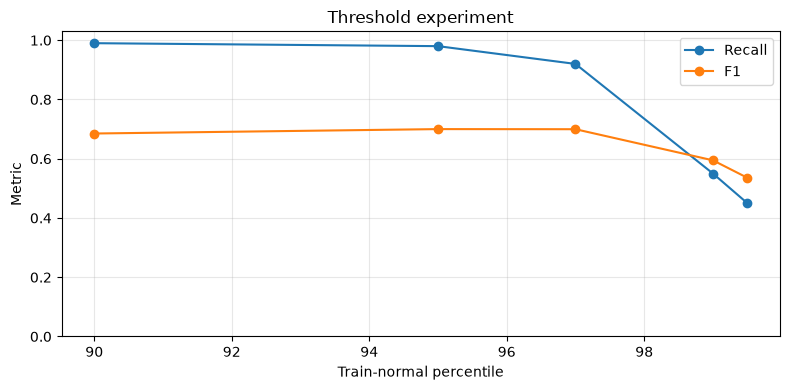

09 OK | 임계값 표/그림 저장


In [9]:
# 09 | 추가 실험 1: 정상 학습 점수 기준 임계값과 FP/FN 변화
rows=[]
for q in (90,95,97,99,99.5):
    t=float(np.percentile(padim_train,q))
    rows.append({"Percentile":q,**evaluate(labels,padim_test,t)})
threshold_df=pd.DataFrame(rows)
threshold_df.to_csv(OUT/"threshold_experiment.csv",index=False,encoding="utf-8-sig")
display(threshold_df[["Percentile","TP","FP","TN","FN","Precision","Recall","F1"]].round(4))
fig,ax=plt.subplots(figsize=(8,4))
for metric in ("Recall","F1"):ax.plot(threshold_df["Percentile"],threshold_df[metric],marker="o",label=metric)
ax.set(title="Threshold experiment",xlabel="Train-normal percentile",ylabel="Metric",ylim=(0,1.03));ax.grid(alpha=.3);ax.legend()
fig.tight_layout();fig.savefig(OUT/"threshold_experiment.png",dpi=140);plt.show();plt.close(fig)
print("09 OK | 임계값 표/그림 저장",flush=True)

### 실험 1 결과와 해석

90백분위에서는 불량 100장 중 99장을 탐지했지만 정상 이미지도 90장이나 불량으로 판정하였다.

95백분위에서는 불량 98장을 탐지했고 정상 82장이 오탐되었다. 반면 99백분위에서는 오탐이 30장으로 줄었지만 불량 45장을 놓쳤다.

99.5백분위에서는 오탐이 23장으로 더 줄었으나 불량 미탐은 55장으로 증가하였다.

이 결과를 통해 임계값을 높인다고 무조건 더 좋은 판정이 되는 것은 아니라는 점을 확인하였다.

실제 제조업에 적용한다면 불량을 놓치는 비용과 정상품을 재검사하는 비용 중 무엇이 더 중요한지에 따라 임계값이 달라질 것이다.

이번 실험에서 95백분위의 F1이 0.7000으로 가장 높았지만, 이는 테스트 결과에서 확인한 값이다. 이 결과만으로 운영 임계값을 확정하면 테스트 데이터에 맞춰지는 문제가 생길 수 있으므로 별도의 검증 데이터에서 임계값을 선택하는 것이 적절하다고 생각한다.


### 6.2 실험 2: 특징 차원에 따른 성능 변화

PaDiM은 특징 차원이 커질수록 더 많은 정보를 이용할 수 있지만, 공분산 행렬의 크기도 함께 증가한다.

따라서 특징을 많이 사용하는 것이 항상 유리한지 궁금하였다.

이번에는 동일한 CNN 특징 캐시를 사용하면서 PaDiM의 특징 차원을 32와 64로 변경하였다. 각 조건에서 AUROC, AUPRC, F1과 계산 시간을 비교하였다.

이 실험의 계산 시간은 특징 추출이 이미 완료된 상태에서의 PaDiM 통계 학습 및 점수 계산 시간이다. 전체 이미지 처리 시간이나 실제 웹 시스템의 추론 지연시간과는 구분할 필요가 있다.


dim 32 | AUROC: 0.835 | 시간: 0.24 초
dim 64 | AUROC: 0.9002 | 시간: 1.9 초


,Dimension,AUROC,AUPRC,F1,Time_seconds
0,32,0.8350,0.6834,0.4444,0.24
1,64,0.9002,0.8194,0.7300,1.90


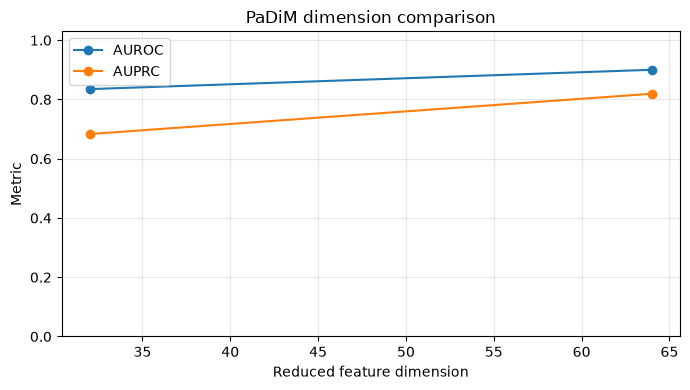

10 OK | 특징 차원 표/그림 저장


In [10]:
# 10 | 추가 실험 2: 동일 캐시로 특징 차원 32 vs 64 (CNN 재추출 없음)
dimension_rows=[]
for dim in (32,64):
    started=time.perf_counter()
    model=fit_padim(train_features,dim=dim)
    train_scores,_=predict_padim(train_features,model)
    test_scores,_=predict_padim(test_features,model)
    metrics=evaluate(labels,test_scores,float(np.percentile(train_scores,99)))
    dimension_rows.append({"Dimension":dim,"Time_seconds":round(time.perf_counter()-started,2),**metrics})
    print("dim",dim,"| AUROC:",round(metrics["AUROC"],4),"| 시간:",dimension_rows[-1]["Time_seconds"],"초",flush=True)
dimension_df=pd.DataFrame(dimension_rows)
dimension_df.to_csv(OUT/"dimension_experiment.csv",index=False,encoding="utf-8-sig")
display(dimension_df[["Dimension","AUROC","AUPRC","F1","Time_seconds"]].round(4))
fig,ax=plt.subplots(figsize=(7,4))
for metric in ("AUROC","AUPRC"):ax.plot(dimension_df.Dimension,dimension_df[metric],marker="o",label=metric)
ax.set(xlabel="Reduced feature dimension",ylabel="Metric",title="PaDiM dimension comparison",ylim=(0,1.03))
ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig(OUT/"dimension_experiment.png",dpi=140);plt.show();plt.close(fig)
print("10 OK | 특징 차원 표/그림 저장",flush=True)

### 실험 2 결과와 해석

32차원에서 AUROC는 0.8350, AUPRC는 0.6834, F1은 0.4444로 나타났다.

64차원에서는 AUROC가 0.9002, AUPRC가 0.8194, F1이 0.7300으로 높아졌다.

반면 계산 시간은 32차원에서 약 0.24초, 64차원에서 약 1.90초로 증가하였다.

이번 조건에서는 특징을 더 많이 사용한 64차원 모델이 성능 면에서 유리했지만 계산 비용도 증가하였다.

다만 코드에서는 차원마다 특징 채널을 무작위로 다시 선택한다. 따라서 차원 수의 영향뿐 아니라 어떤 채널이 선택되었는지도 결과에 영향을 줄 수 있다.

이 실험만으로 특징 차원을 늘리면 항상 성능이 좋아진다고 결론 내릴 수는 없다. 이후에는 동일한 채널 선택 순서를 유지하고 여러 seed에서 반복하는 방식으로 검증해보고 싶다.

또한 기본 모델은 48차원이고 이번 실험은 32차원과 64차원을 비교한 것이므로, 최종 모델을 변경하려면 같은 조건에서 48차원도 함께 재평가하는 것이 필요하다.


## 7. 다른 이상 탐지 모델과 비교

### 7.1 One-Class SVM

PaDiM만으로 평가하면 다른 방법에 비해 어떤 장단점이 있는지 판단하기 어려우므로 One-Class SVM도 적용하였다.

One-Class SVM은 정상 데이터의 특징을 이용해 정상 영역의 경계를 학습하고, 경계에서 벗어난 데이터를 이상으로 판단한다.

이번 구현에서는 CNN의 패치 특징을 위치별 평균으로 합쳐 이미지 전체의 특징 벡터를 만들었다.

PaDiM이 위치별 정상 분포를 계산하는 것과 달리, 이 방식의 One-Class SVM은 공간 정보를 상당 부분 평균화한다는 차이가 있다.


In [11]:
# 11 | 기준 모델 One-Class SVM (정상 이미지 전역 CNN 특징으로 학습)
def mean_features(mm):
    out=np.zeros((len(mm),mm.shape[-1]),dtype=np.float32)
    for i in range(0,len(mm),16):
        batch=np.asarray(mm[i:i+16],dtype=np.float32)
        out[i:i+len(batch)]=batch.mean(axis=1)
    return out
scaler=StandardScaler()
svm=OneClassSVM(nu=.1,kernel="rbf",gamma="scale")
svm_train=mean_features(train_features)
svm_test=mean_features(test_features)
svm.fit(scaler.fit_transform(svm_train))
svm_normal_scores=-svm.decision_function(scaler.transform(svm_train)).ravel()
svm_scores=-svm.decision_function(scaler.transform(svm_test)).ravel()
results["One-Class SVM"]=evaluate(labels,svm_scores,float(np.percentile(svm_normal_scores,99)))
scores_by_method["One-Class SVM"]=svm_scores
print("11 OK | SVM AUROC:",round(results["One-Class SVM"]["AUROC"],4),flush=True)

11 OK | SVM AUROC: 0.7806


### One-Class SVM 결과

One-Class SVM의 AUROC는 0.7806이었다.

불량 100장을 모두 탐지해 Recall은 1.0이었지만, 정상 이미지 201장 중 158장도 불량으로 판정하였다.

불량을 놓치지 않았다는 점은 좋지만 오탐이 지나치게 많았다. 이 상태로 실제 검사에 적용하면 정상 제품에 대한 재검사가 크게 증가할 가능성이 있다.

또한 이번 SVM은 패치 특징을 평균화한 전역 특징을 사용하므로, PaDiM보다 결함의 위치 정보를 활용하기 어렵다. 단순히 알고리즘 이름만으로 성능을 비교하기보다 어떤 특징을 입력했는지도 함께 고려해야 한다고 생각한다.


### 7.2 CNN AutoEncoder

AutoEncoder는 입력 이미지를 압축한 뒤 다시 복원하는 과정을 학습한다.

정상 이미지로 학습한 경우 정상 패턴은 비교적 잘 복원하고, 학습하지 않은 이상 패턴은 복원 오차가 커질 수 있다는 점을 이용한다.

이번에는 구조가 단순한 CNN AutoEncoder를 구성하였다. 입력은 64×64 크기로 변환하였고, 정상 이미지만 사용해 학습하였다.

다만 학습 시간을 줄이기 위해 2 epoch만 실행하였다. 학습 손실의 변화는 확인할 수 있지만, 충분히 수렴한 모델과 동일하게 비교할 수 있는 조건은 아니다.


In [12]:
# 12 | 경량 AutoEncoder (기본 2 epoch, 실습용 비교)
class SmallAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Conv2d(3,16,4,2,1),nn.ReLU(),nn.Conv2d(16,32,4,2,1),nn.ReLU(),nn.Conv2d(32,64,4,2,1),nn.ReLU())
        self.decoder=nn.Sequential(nn.ConvTranspose2d(64,32,4,2,1),nn.ReLU(),nn.ConvTranspose2d(32,16,4,2,1),nn.ReLU(),nn.ConvTranspose2d(16,3,4,2,1),nn.Sigmoid())
    def forward(self,x):return self.decoder(self.encoder(x))
MEAN=torch.tensor([.485,.456,.406]).view(1,3,1,1).to(DEVICE)
STD=torch.tensor([.229,.224,.225]).view(1,3,1,1).to(DEVICE)
def input_ae(x):
    rgb=(x*STD+MEAN).clamp(0,1)
    return F.interpolate(rgb,size=(64,64),mode="bilinear",align_corners=False)
ae=SmallAE().to(DEVICE)
opt=torch.optim.Adam(ae.parameters(),lr=.001)
ae_loader=DataLoader(train_data,batch_size=BATCH,shuffle=True,num_workers=0)
for epoch in range(AE_EPOCHS):
    ae.train();losses=[]
    for batch in tqdm(ae_loader,desc=f"AE epoch {epoch+1}/{AE_EPOCHS}"):
        x=input_ae(batch["image"].to(DEVICE))
        pred=ae(x);loss=F.mse_loss(pred,x)
        opt.zero_grad();loss.backward();opt.step()
        losses.append(loss.item())
    print("AE",epoch+1,"/",AE_EPOCHS,"loss",round(float(np.mean(losses)),6),flush=True)
ae.eval()
def infer_ae(loader):
    ans=[]
    with torch.inference_mode():
        for batch in loader:
            x=input_ae(batch["image"].to(DEVICE));rec=ae(x)
            ans.extend((rec-x).pow(2).mean(dim=(1,2,3)).cpu().tolist())
    return np.array(ans)
ae_train=infer_ae(train_loader);ae_test=infer_ae(test_loader)
results["AutoEncoder (2 epochs)"]=evaluate(labels,ae_test,float(np.percentile(ae_train,99)))
scores_by_method["AutoEncoder (2 epochs)"]=ae_test
torch.save(ae.cpu().state_dict(),OUT/"autoencoder_weights.pt");ae.to(DEVICE)
print("12 OK | AE AUROC:",round(results["AutoEncoder (2 epochs)"]["AUROC"],4),flush=True)

AE epoch 1/2: 100%|██████████| 25/25 [00:06<00:00,  3.64it/s]

AE 1 / 2 loss 0.099472



AE epoch 2/2: 100%|██████████| 25/25 [00:05<00:00,  4.58it/s]

AE 2 / 2 loss 0.047873


12 OK | AE AUROC: 0.4588


### AutoEncoder 결과

학습 손실은 첫 번째 epoch에서 0.099472, 두 번째 epoch에서 0.047873으로 감소하였다.

하지만 이미지 단위 AUROC는 0.4588이었고, 설정한 임계값에서는 불량 100장을 모두 놓쳤다.

손실이 감소했다는 것은 입력을 복원하는 방향으로 학습이 진행되고 있음을 보여주지만, 그것이 정상과 불량을 잘 구별한다는 의미는 아니라는 점을 확인하였다.

특히 이번에는 2 epoch만 학습했기 때문에 충분한 학습 후에도 같은 결과가 나타날지는 판단하기 어렵다.

향후 epoch을 늘려 복원 손실과 AUROC가 함께 어떻게 변하는지 확인하면 더 의미 있는 비교가 될 것 같다.


## 8. 모델별 결과 비교와 시각화

### 8.1 세 모델의 이미지 단위 성능 비교

PaDiM, One-Class SVM, AutoEncoder의 결과를 한 표에 정리하고 ROC 곡선을 비교하였다.

ROC 그래프에서는 곡선이 왼쪽 위에 가까울수록 정상과 이상을 구별하는 능력이 높은 편이며, AUROC가 클수록 전반적인 구분 성능이 좋다고 볼 수 있다.

추가로 정상과 불량 이미지의 이상 점수 분포를 확인하였다. 두 분포가 많이 겹친다면 어떤 임계값을 사용하더라도 오탐과 미탐이 함께 발생할 가능성이 있다.

마지막 그림에서는 PaDiM의 패치별 이상 점수를 히트맵으로 나타냈다. 이상 여부를 판단하는 것과 실제 결함 위치를 정확하게 찾는 것은 서로 다른 문제이므로, 위치 탐지 성능은 별도로 검증할 필요가 있다.


,AUROC,AUPRC,F1,Precision,Recall,TN,FP,FN,TP,Threshold
Method,,,,,,,,,,
PaDiM,0.8516,0.7092,0.5946,0.6471,0.55,171,30,45,55,8.1749
One-Class SVM,0.7806,0.6171,0.5587,0.3876,1.00,43,158,0,100,0.0013
AutoEncoder (2 epochs),0.4588,0.3102,0.0000,0.0000,0.00,201,0,100,0,0.0320


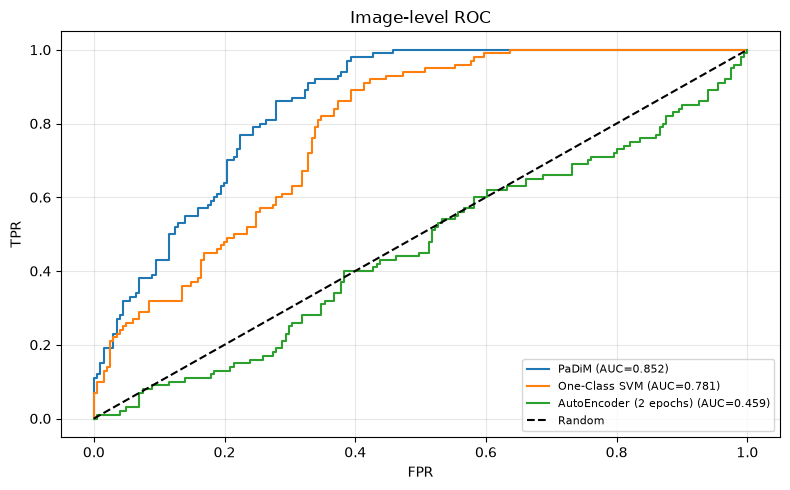

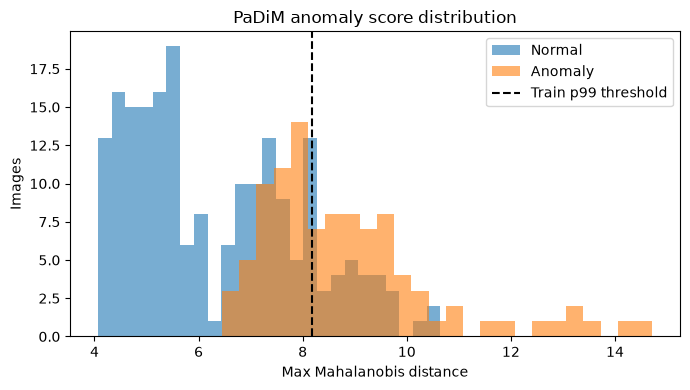

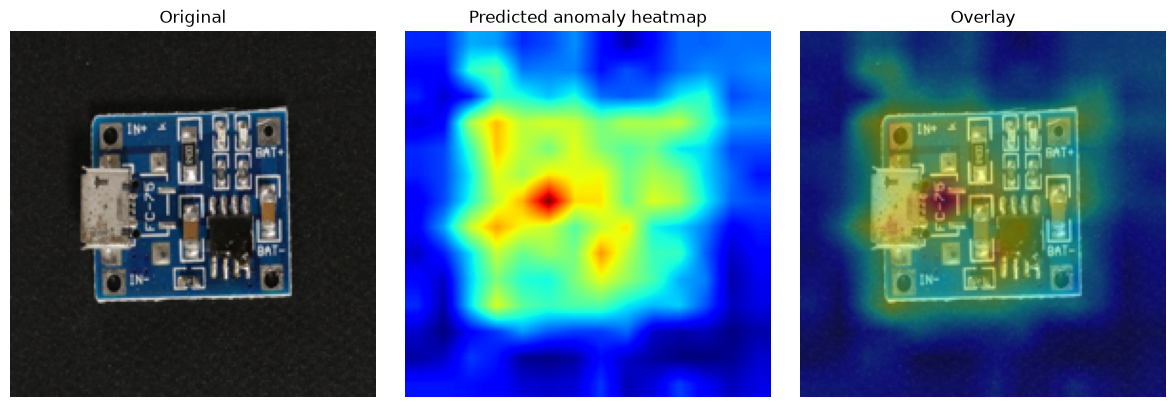

13 OK | 모델 비교표/ROC/점수분포/이상맵 저장


In [13]:
# 13 | 그래프/결과 자동 저장
comparison=pd.DataFrame.from_dict(results,orient="index")
comparison.index.name="Method"
comparison.to_csv(OUT/"model_comparison.csv",encoding="utf-8-sig")
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(8,5))
for name,s in scores_by_method.items():
    fpr,tpr,_=roc_curve(labels,s)
    ax.plot(fpr,tpr,label=f"{name} (AUC={results[name]['AUROC']:.3f})")
ax.plot([0,1],[0,1],"k--",label="Random");ax.set(xlabel="FPR",ylabel="TPR",title="Image-level ROC")
ax.grid(alpha=.3);ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/"roc_comparison.png",dpi=140);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(padim_test[labels==0],bins=25,alpha=.6,label="Normal")
ax.hist(padim_test[labels==1],bins=25,alpha=.6,label="Anomaly")
ax.axvline(threshold,color="black",ls="--",label="Train p99 threshold")
ax.set(title="PaDiM anomaly score distribution",xlabel="Max Mahalanobis distance",ylabel="Images");ax.legend()
fig.tight_layout();fig.savefig(OUT/"score_distribution.png",dpi=140);plt.show();plt.close(fig)
i=int(np.where(labels==1)[0][0])
with Image.open(test_rows[i]["image"]) as im:base=np.asarray(im.convert("RGB").resize((IMAGE_SIZE,IMAGE_SIZE)))
small=padim_maps[i]
big=np.asarray(Image.fromarray(small.astype(np.float32)).resize((IMAGE_SIZE,IMAGE_SIZE),Image.BILINEAR))
scale=(big-big.min())/(np.ptp(big)+1e-8)
heat=(plt.get_cmap("jet")(scale)[...,:3]*255).astype(np.uint8)
merged=np.clip(.6*base.astype(np.float32)+.4*heat.astype(np.float32),0,255).astype(np.uint8)
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,img,title in zip(axs,[base,heat,merged],["Original","Predicted anomaly heatmap","Overlay"]):
    ax.imshow(img);ax.set_title(title);ax.axis("off")
fig.tight_layout();fig.savefig(OUT/"predicted_anomaly_map.png",dpi=140);plt.show();plt.close(fig)
print("13 OK | 모델 비교표/ROC/점수분포/이상맵 저장",flush=True)

### 전체 비교 결과에 대한 생각

세 모델 중 이번 실행 조건에서 이미지 단위 AUROC가 가장 높았던 모델은 PaDiM이었다.

PaDiM은 0.8516, One-Class SVM은 0.7806, AutoEncoder는 0.4588로 나타났다.

그러나 모델별 입력 특징과 학습 조건이 다르고, 특히 AutoEncoder의 학습 횟수가 적기 때문에 이를 모델 자체의 절대적인 성능 순위로 해석하기는 어렵다.

PaDiM의 이상 점수 분포에서도 정상과 불량이 완전히 분리되지 않는 것을 확인할 수 있었다. 이 분포가 겹치는 부분이 오탐과 미탐을 발생시키는 원인 중 하나라고 볼 수 있다.

예측 히트맵은 모델이 어느 위치를 이상하게 판단했는지 보여주지만, 시각적으로 그럴듯해 보이는 것만으로 위치 정확도가 검증되지는 않는다.

실제 결함 마스크와 예측 히트맵을 같은 이미지에서 비교하고 Pixel-level AUROC나 IoU를 계산하는 실험이 추가로 필요하다.


## 9. 실험 결과 정리

### 9.1 결과 파일 저장

이번 실험에서 계산한 모델별 평가 지표, 임계값 실험, 특징 차원 실험, ROC 그래프, 이상 점수 분포 및 예측 히트맵을 파일로 저장하였다.

결과를 단순히 화면에서 확인하는 것보다 파일로 남겨두면 이후 다른 실험 조건과 비교하기 편리하다.

또한 모델 파라미터를 저장해 다시 학습하지 않고도 결과를 활용할 수 있도록 하였다.

저장된 실험 결과는 padim_outputs 폴더에서 확인할 수 있다.


In [14]:
# 14 | 과제 제출용 결과 보고서 자동 작성 + 산출물 검수
lines=["# VisA PCB4 이상 탐지 실습 결과","",f"- 학습 정상: {len(train_rows)}장 / 전체 학습 분할 {len(train_full)}장",
       f"- 테스트 정상: {(labels==0).sum()}장 / 불량: {(labels==1).sum()}장",
       f"- ResNet18 상태: {WEIGHT_STATUS} / 이미지 {IMAGE_SIZE} / GRID {GRID}",
       f"- AE epoch: {AE_EPOCHS}","","## 이미지 단위 평가",
       "| Method | AUROC | AUPRC | F1 | FP | FN |","|---|---:|---:|---:|---:|---:|"]
for name,r in results.items():
    lines.append(f"| {name} | {r['AUROC']:.4f} | {r['AUPRC']:.4f} | {r['F1']:.4f} | {r['FP']} | {r['FN']} |")
lines += ["","## 추가 실험","- Threshold: 정상 학습 점수 백분위 90,95,97,99,99.5에 따른 FP/FN 비교. threshold_experiment.csv/png 참조.",
          "- Feature dimension: 32 vs 64 차원 비교. dimension_experiment.csv/png 참조.",
          "","## 한계/해석",
          "- 기본 실행은 학습 분할 전체가 아니라 일부 정상 영상으로 학습하여 전체 804장 조건과 직접 비교할 수 없습니다.",
          "- 임계값은 학습 정상 점수로 계산했고 별도 검증 세트 사용이 권장됩니다.",
          "- AutoEncoder 2 epoch은 빠른 비교용이며 최적 성능을 보장하지 않습니다.",
          "- AUROC/AUPRC는 이미지 수준이며 픽셀 수준 마스크 평가가 아닙니다."]
if WEIGHT_STATUS!="pretrained":lines.append("- 주의: 무작위 ResNet18 가중치로 실행했으므로 성능을 신뢰할 수 있는 최종 값으로 주장하면 안 됩니다.")
(OUT/"result_report.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
files=["padim_model_state.npz","threshold_experiment.csv","threshold_experiment.png","dimension_experiment.csv","dimension_experiment.png",
       "autoencoder_weights.pt","model_comparison.csv","roc_comparison.png","score_distribution.png","predicted_anomaly_map.png","result_report.md"]
if valid_mask_row:files+=["ground_truth_preview.png"]
missing=[f for f in files if not (OUT/f).is_file()]
assert not missing,"산출물 누락: "+str(missing)
assert len(padim_test)==len(labels) and np.isfinite(padim_maps).all()
for key,r in results.items():
    assert 0<=r["AUROC"]<=1 and 0<=r["AUPRC"]<=1 and 0<=r["F1"]<=1,key
print("="*50)
print("14 전체 실험 실행 및 검수 완료 | 결과 폴더:",OUT)
print("모델:",len(results),"| 테스트:",len(labels),"| 산출물:",len(files))
if WEIGHT_STATUS!="pretrained":print("경고: 사전학습 가중치 사용 실패 — 점수 해석 주의")
print("Jupyter Ctrl+S로 실행된 노트북을 저장하세요.")
print("="*50,flush=True)

14 전체 실험 실행 및 검수 완료 | 결과 폴더: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\07_Anomaly_detection\padim_outputs
모델: 3 | 테스트: 301 | 산출물: 12
Jupyter Ctrl+S로 실행된 노트북을 저장하세요.


### 산출물 확인

실험 결과는 padim_outputs 폴더에 저장되었으며, 실행 로그에서는 총 12개의 산출물이 확인되었다.

모델별 비교표와 추가 실험의 CSV 파일, 그래프 및 모델 상태 파일을 저장하였다.

이후에는 각 실험 조건을 변경한 결과를 같은 형식으로 정리하면 비교가 수월할 것으로 생각한다.

단, 현재 자동 생성된 결과 보고서는 기본적인 수치와 실행 조건 중심이다. 실험을 통해 알게 된 점과 한계는 본 노트북의 해석 부분에 별도로 기록하였다.


## 10. Gradio 웹 인터페이스 검토

강의 목표에는 이미지 입력에 대한 이상 탐지 결과를 웹에서 확인하는 과정도 포함되어 있다.

이를 위해 이미지 입력, 정상 또는 불량 판정, 이상 점수 및 히트맵을 출력하는 Gradio 코드가 포함되어 있다.

다만 이번에 저장된 실행 결과에서는 ENABLE_GRADIO가 False로 설정되어 있어 실제 웹 인터페이스를 실행하지 않았다.

따라서 Gradio 구현 코드는 포함되어 있지만 웹에서의 실제 추론 성공 여부나 처리속도까지 검증했다고 보기는 어렵다. 이 부분은 이후 별도 실험으로 확인할 예정이다.


In [15]:
# 15 | 옵션: 공개 링크 없는 Gradio
ENABLE_GRADIO=False
if ENABLE_GRADIO:
    try:
        import gradio as gr
        def infer(pil):
            with torch.inference_mode():
                x=transform(pil.convert("RGB")).unsqueeze(0).to(DEVICE)
                feats=extractor(x).cpu().numpy()[:,:,padim["ids"]].astype(np.float64)
            diff=feats-padim["mean"][None]
            dist=np.sqrt(np.maximum(np.einsum("bpi,pij,bpj->bp",diff,padim["inv"],diff,optimize=True),0))
            value=float(dist.max())
            mini=dist[0].reshape(GRID,GRID).astype(np.float32)
            big=np.asarray(Image.fromarray(mini).resize((IMAGE_SIZE,IMAGE_SIZE),Image.BILINEAR))
            scaled=(big-big.min())/(np.ptp(big)+1e-8)
            cmap=(plt.get_cmap("jet")(scaled)[...,:3]*255).astype(np.uint8)
            src=np.asarray(pil.convert("RGB").resize((IMAGE_SIZE,IMAGE_SIZE)))
            overlay=np.clip(.6*src+.4*cmap,0,255).astype(np.uint8)
            label="Anomaly" if value>=threshold else "Normal"
            return f"{label} | score={value:.4f} | threshold={threshold:.4f}",cmap,overlay
        gr.Interface(infer,inputs=gr.Image(type="pil"),outputs=[gr.Textbox(),gr.Image(type="numpy"),gr.Image(type="numpy")],title="PCB4 PaDiM anomaly detection").launch(share=False,prevent_thread_lock=True)
    except Exception as exc:print("Gradio 선택 기능 실패(핵심 결과 이미 저장):",repr(exc))
else:print("15 OK | Gradio 자동 실행 생략 — 제출 결과는 이미 생성됐습니다.")

15 OK | Gradio 자동 실행 생략 — 제출 결과는 이미 생성됐습니다.


### 현재 확인된 범위

이번 실행에서는 Gradio 서버를 시작하지 않았으며 화면에는 자동 실행을 생략했다는 메시지만 출력되었다.

따라서 실시간 웹 서비스가 정상적으로 작동한다고 주장할 수는 없다.

향후 Gradio를 활성화한 뒤 정상 이미지와 불량 이미지를 직접 입력하여 판정 점수, 히트맵 및 처리 시간을 확인하는 실험을 진행하고자 한다.


# 11. 최종 정리와 개인 회고

## 11.1 프로젝트 목표에 대한 평가

이번 실습에서는 VisA PCB4 데이터를 활용해 PaDiM 모델을 구성하고 정상과 불량을 구분하는 과정을 수행하였다.

PaDiM 외에도 One-Class SVM과 AutoEncoder를 적용했으며, AUROC와 AUPRC 같은 이미지 단위 지표를 비교하였다.

추가로 기본 실습에서 한 단계 더 확인해보고 싶었던 임계값 변화와 특징 차원 변화 실험을 진행하였다.

가장 의미 있었던 부분은 AUROC가 비교적 높게 나오더라도 임계값을 적용한 실제 판정에서는 불량을 많이 놓칠 수 있다는 점이었다.

처음에는 AUROC가 높으면 좋은 모델이라고 생각했지만, 이번에는 FP와 FN을 함께 확인하면서 실제 검사 목적에 따라 평가 기준이 달라져야 한다는 것을 알게 되었다.

또한 특징 차원이 높아질수록 성능이 개선된 결과도 확인했지만, 계산 비용과 채널 선택 조건까지 함께 살펴봐야 한다는 점을 배웠다.

## 11.2 이번 작업에서 추가로 진행한 내용

기존 모델 비교뿐 아니라 PaDiM 임계값을 다섯 가지 조건으로 변경해 Precision, Recall, F1과 오탐 및 미탐의 변화를 확인하였다.

또한 특징 차원을 32와 64로 변경하여 성능 및 계산 시간을 비교하였다.

실행 과정에서는 CNN 특징을 디스크에 저장하고 재사용하는 방법을 적용하였다. 덕분에 추가 실험에서 특징 추출 과정을 반복할 필요가 없었다.

다만 다른 제품군의 추가 데이터셋으로 일반화 성능을 검증하거나, 실제 GT 마스크를 이용한 Pixel-level 정량 평가는 아직 진행하지 못했다.

이 두 가지는 이번 프로젝트에서 남은 과제로 정리하였다.

## 11.3 Keep

이번에는 하나의 지표만 확인하지 않고 AUROC, AUPRC, Precision, Recall, F1과 혼동행렬을 함께 살펴본 점이 좋았다.

특히 임계값을 변경하면서 불량 탐지율과 오탐 사이의 관계를 직접 확인한 방법은 앞으로도 유지하고 싶다.

실행 결과를 CSV와 그림으로 저장해 나중에 다시 비교할 수 있도록 한 점도 유용했다.

## 11.4 Problem

가장 큰 문제는 기본 PaDiM 설정에서 불량 미탐이 적지 않았다는 점이다.

99백분위 임계값에서는 불량 100장 중 45장을 놓쳤고, 정상 이미지 30장도 불량으로 판정하였다.

또한 학습 이미지를 200장으로 제한했기 때문에 충분한 정상 데이터를 사용했을 때 성능이 어떻게 달라지는지 확인하지 못했다.

특징 차원 실험에서는 차원별로 선택한 특징 채널도 달라질 수 있어 차원 수 자체의 영향만을 분리하지 못했다.

AutoEncoder도 2 epoch만 학습했기 때문에 모델 간 비교 조건이 충분히 공정하지 않았다.

## 11.5 Try

앞으로 가장 먼저 해보고 싶은 것은 학습 데이터 수에 따른 성능 변화 분석이다.

현재 사용한 정상 이미지 200장과 원래 학습 분할 전체인 804장을 비교하면 정상 데이터 확보가 이상 탐지 성능에 얼마나 중요한지 확인할 수 있을 것이다.

다음으로는 특징 차원을 변경하되 채널 선택 순서를 고정하고, 반복 실험을 통해 성능의 일관성을 확인하고 싶다.

또한 예측 히트맵과 실제 결함 마스크를 비교해 이미지 판정 성능뿐 아니라 결함 위치 탐지 성능도 평가해보고 싶다.

## 11.6 Action After Review

첫 번째 후속 실험에서는 입력 이미지 크기, 특징 차원, 임계값 선정 방법을 동일하게 유지하고 정상 학습 이미지 수만 200장과 804장으로 변경한다.

두 조건의 AUROC, AUPRC, F1을 비교하여 학습 데이터 수 증가가 실제로 유의미한 개선을 가져오는지 살펴본다.

두 번째 후속 실험에서는 특징 차원을 32, 48, 64로 변경한다. 채널 선택 순서를 고정하고 여러 random seed로 반복해 평균 성능과 변동성을 비교한다.

세 번째 후속 실험에서는 VisA의 다른 PCB 카테고리에도 동일한 방법을 적용한다. 각 카테고리의 정상 이미지로 별도 학습한 뒤 PCB4와 결과를 비교하여 제품 종류에 따른 성능 차이를 확인한다.

네 번째 후속 실험에서는 GT 마스크와 이상 점수 맵을 이용해 Pixel-level 평가를 수행한다.

마지막으로 Gradio를 직접 실행하고 정상 및 불량 이미지를 입력해 판정 결과와 처리 시간을 확인한다. 실제 처리속도가 측정되면 모델 정확도와 시스템 속도를 함께 고려할 수 있을 것이다.

## 11.7 다른 사람의 피드백과 추가 검토

현재 노트북에는 다른 사람의 피드백을 받거나 이를 반영한 기록이 없다.

향후 피드백을 받는다면 모델 성능뿐 아니라 데이터 분할 방법, 임계값 선정 기준, 모델 간 비교의 공정성에 대한 의견을 우선적으로 확인하고자 한다.

피드백을 받은 이후에는 어떤 의견을 반영했는지와 수정 전후의 차이를 이 부분에 기록할 예정이다.

## 11.8 마무리

이번 실습을 통해 이상 탐지 모델이 단순히 불량 이미지를 찾아내는 것만으로 완성되는 것은 아니라는 점을 알게 되었다.

정상 데이터 구성, 특징 추출 방식, 임계값 선정, 계산 비용에 따라 결과가 달라졌고, 이미지 전체의 이상 여부와 정확한 결함 위치를 평가하는 것도 구분해야 했다.

아직 학습 데이터 수와 다른 제품군에 대한 검증이 부족하지만, 이번에 진행한 실험을 바탕으로 이후에는 결과의 수치뿐 아니라 그 수치가 나온 원인까지 살펴보고 싶다.

# 12. 참고 자료

강의자료: 제조업 실시간 이상 탐지 시스템 구축 실습

PaDiM: A Patch Distribution Modeling Framework for Anomaly Detection and Localization

https://arxiv.org/abs/2011.08785
